In [1]:
import pandas as pd
import seaborn as sns

titanic = sns.load_dataset('titanic')

In [2]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
titanic.shape   # (891, 15)

(891, 15)

In [5]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
titanic.groupby('pclass')['fare'].agg(['mean', 'median', 'count', 'size'])

,mean,median,count,size
pclass,,,,
1,84.154687,60.2875,216,216
2,20.662183,14.2500,184,184
3,13.675550,8.0500,491,491


In [7]:
titanic.isnull().mean() *100  # процент пропусков

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64

In [8]:
titanic['age'].fillna(titanic['age'].median(), inplace= True)

C:\Users\stgay\AppData\Local\Temp\ipykernel_14900\3162100333.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic['age'].fillna(titanic['age'].median(), inplace= True)


In [9]:
titanic = titanic.drop(columns='deck')

In [10]:
titanic = titanic.dropna(subset=['embarked'])

In [11]:
titanic.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [12]:
ready_dataframe_X = titanic.drop(columns=['alive', 'who', 'adult_male', 'alone', 'class', 'embark_town'])

In [13]:
ready_dataframe_X_dummies = pd.get_dummies(ready_dataframe_X, columns = ['embarked', 'sex'], drop_first= True)

In [14]:
ready_dataframe_X_dummies.head()

,survived,pclass,age,sibsp,parch,fare,embarked_Q,embarked_S,sex_male
0,0,3,22.0,1,0,7.2500,False,True,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,True,False
3,1,1,35.0,1,0,53.1000,False,True,False
4,0,3,35.0,0,0,8.0500,False,True,True


In [15]:
ready_dataframe_X_dummies.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    889 non-null    int64  
 1   pclass      889 non-null    int64  
 2   age         889 non-null    float64
 3   sibsp       889 non-null    int64  
 4   parch       889 non-null    int64  
 5   fare        889 non-null    float64
 6   embarked_Q  889 non-null    bool   
 7   embarked_S  889 non-null    bool   
 8   sex_male    889 non-null    bool   
dtypes: bool(3), float64(2), int64(4)
memory usage: 51.2 KB


In [16]:
# Считаем корреляцию всех признаков с целевой переменной 'survived'
correlations = ready_dataframe_X_dummies.corr()['survived'].sort_values(ascending=False)

print("=== ТОП-3 положительных (увеличивают шанс выжить) ===")
print(correlations.head(4)) # head(4), потому что первым будет сам survived (1.0)

print("\n=== ТОП-3 отрицательных (уменьшают шанс выжить) ===")
print(correlations.tail(3))

=== ТОП-3 положительных (увеличивают шанс выжить) ===
survived      1.000000
fare          0.255290
parch         0.083151
embarked_Q    0.004536
Name: survived, dtype: float64

=== ТОП-3 отрицательных (уменьшают шанс выжить) ===
embarked_S   -0.151777
pclass       -0.335549
sex_male     -0.541585
Name: survived, dtype: float64


------------------------------------------- СОЗДАНИЕ ML МОДЕЛИ   ----------------------------------------------------------------

In [17]:
y = ready_dataframe_X_dummies['survived']
X = ready_dataframe_X_dummies.drop(columns = ['survived'])

In [18]:
X.head()

,pclass,age,sibsp,parch,fare,embarked_Q,embarked_S,sex_male
0,3,22.0,1,0,7.2500,False,True,True
1,1,38.0,1,0,71.2833,False,False,False
2,3,26.0,0,0,7.9250,False,True,False
3,1,35.0,1,0,53.1000,False,True,False
4,3,35.0,0,0,8.0500,False,True,True


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

In [21]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# Создаем "глупую" модель, которая всегда выбирает самый частый класс
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

# Предсказываем и считаем точность
baseline_pred = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, baseline_pred)

print(f"Baseline Accuracy (всегда предсказываем 0): {baseline_acc:.4f}")

Baseline Accuracy (всегда предсказываем 0): 0.6124


In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"LogisticRegression Accuracy: {accuracy:.4f}")

LogisticRegression Accuracy: 0.7809


In [24]:
import pandas as pd

# Собираем веса в табличку
coefs = pd.DataFrame({
    'feature': X.columns,
    'weight': model.coef_[0]
}).sort_values(by='weight', ascending=False)

print(coefs)

      feature    weight
4        fare  0.001747
1         age -0.043261
3       parch -0.053213
5  embarked_Q -0.064820
2       sibsp -0.375558
6  embarked_S -0.482159
0      pclass -1.122366
7    sex_male -2.630720


In [38]:
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"LogisticRegression Accuracy: {accuracy:.4f}")

LogisticRegression Accuracy: 0.7809


Матрица ошибок (числа):
 [[85 24]
 [15 54]]


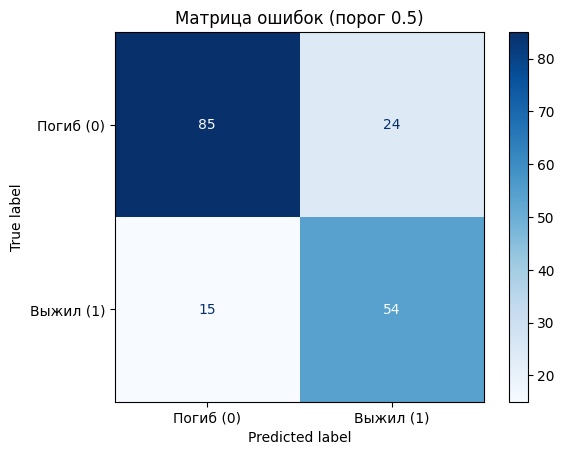

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Считаем матрицу ошибок на основе предсказаний y_pred (из Day 10)
cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок (числа):\n", cm)

# Рисуем ее красиво
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Погиб (0)', 'Выжил (1)'])
disp.plot(cmap='Blues')
plt.title('Матрица ошибок (порог 0.5)')
plt.show()

In [40]:
from sklearn.metrics import classification_report

print("=== Отчет по метрикам (порог 0.5) ===")
print(classification_report(y_test, y_pred, target_names=['Погиб (0)', 'Выжил (1)']))

=== Отчет по метрикам (порог 0.5) ===
              precision    recall  f1-score   support

   Погиб (0)       0.85      0.78      0.81       109
   Выжил (1)       0.69      0.78      0.73        69

    accuracy                           0.78       178
   macro avg       0.77      0.78      0.77       178
weighted avg       0.79      0.78      0.78       178



In [41]:
# Получаем вероятности (а не жесткие 0/1)
y_probs = model.predict_proba(X_test)[:, 1] 

# Ставим свой порог 0.7 (вместо стандартного 0.5)
custom_pred = (y_probs > 0.7).astype(int)

print("=== Отчет по метрикам (порог 0.7) ===")
print(classification_report(y_test, custom_pred, target_names=['Погиб (0)', 'Выжил (1)']))

=== Отчет по метрикам (порог 0.7) ===
              precision    recall  f1-score   support

   Погиб (0)       0.81      0.92      0.86       109
   Выжил (1)       0.83      0.65      0.73        69

    accuracy                           0.81       178
   macro avg       0.82      0.78      0.80       178
weighted avg       0.82      0.81      0.81       178



In [42]:
(y_probs > 0.7).astype(int)

array([0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1])

ROC-AUC: 0.8515


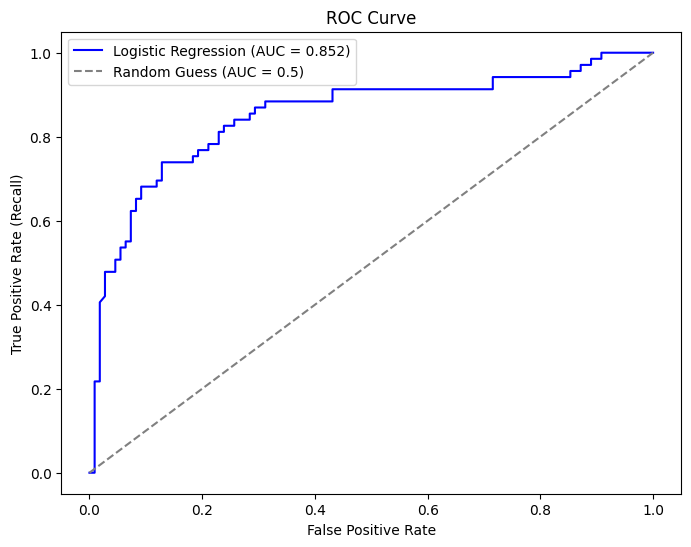

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. Берем вероятности (мы делали это в Day 11)
y_probs = model.predict_proba(X_test)[:, 1]

# 2. Считаем площадь (AUC)
auc_score = roc_auc_score(y_test, y_probs)
print(f"ROC-AUC: {auc_score:.4f}")

# 3. Строим график
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_score:.3f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [44]:
from sklearn.model_selection import cross_val_score

# Берем нашу модель LogisticRegression(max_iter=1000)
# Оцениваем на ВСЕХ данных X и y (без train_test_split, CV сам все сделает)
cv_scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')

print(f"Результаты 5 фолдов: {cv_scores}")
print(f"Средняя Accuracy: {cv_scores.mean():.4f}")
print(f"Стандартное отклонение: {cv_scores.std():.4f}")

Результаты 5 фолдов: [0.78651685 0.78651685 0.78651685 0.76966292 0.82485876]
Средняя Accuracy: 0.7908
Стандартное отклонение: 0.0182


In [48]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Создаем конвейер: сначала масштабирование, потом модель
pipe = Pipeline([
    ('scaler', StandardScaler()), 
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Теперь кросс-валидация с пайплайном (никакой утечки)
pipeline_cv_scores = cross_val_score(pipe, X, y, cv=5, scoring='accuracy')

print(f"Средняя Accuracy с Pipeline: {pipeline_cv_scores.mean():.5f}")

Средняя Accuracy с Pipeline: 0.78519
